# Front Size Analysis

This notebook investigates the relationship between the Pareto-front sizes
produced by `OptimalDecode` and various EVRP instance parameters.

**Methodology:**  For each experiment we sweep one parameter while keeping the
rest at baseline values.  For every parameter value we generate **32 random
instances**, and for each instance we produce **32 KNN permutations** and
record the front sizes after decoding.

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import json

from evrp_decoder import OptimalDecode, Solution
from evrp_decoder.generators import generate_instance, knn_permutation

## Baseline parameters & helpers

In [2]:
# Baseline instance parameters
BASELINE = dict(
    customer_cnt=100,
    charging_station_cnt=10,
    battery_capacity=2.0,
    cargo_capacity=200.0,
    max_demand = 10.0,
    energy_consumption=1.0,
)

N_INSTANCES = 32   # random instances per parameter value
N_PERMS = 32       # KNN permutations per instance
KNN_K = 4          # k for knn_permutation
UPPER_BOUND = float("inf")  # generous upper bound for decode

# Publication style
plt.rcParams.update({
    "font.family":        "serif",
    "font.serif":         ["Computer Modern Roman", "CMU Serif", "Times New Roman", "DejaVu Serif"],
    "mathtext.fontset":   "cm",
    "font.size":          6,
    "axes.labelsize":     7,
    "xtick.labelsize":    5,
    "ytick.labelsize":    5,
    "figure.dpi":         200,
    "savefig.dpi":        600,
    "savefig.bbox":       "tight",
    "savefig.pad_inches": 0.02,
})

In [3]:
def collect_front_sizes(param_name, param_values):
    """Sweep *param_name* over *param_values*, return dict mapping value -> list of front sizes."""
    results = {}  # param_value -> list[float]  (mean front size per (instance, perm))

    for val in tqdm(param_values, desc=param_name):
        sizes = []
        params = {**BASELINE, param_name: val}

        for inst_seed in range(N_INSTANCES):
            inst = generate_instance(**params, rng=random.Random(inst_seed))
            decoder = OptimalDecode(inst)

            for perm_seed in range(N_PERMS):
                perm = knn_permutation(inst, KNN_K, rng=random.Random(perm_seed))

                sol = Solution(inst)
                sol.routes = perm
                decoder.decode(sol, UPPER_BOUND)

                # Record mean front size across all fronts
                n_fronts = decoder.front_cnt()
                if n_fronts > 0:
                    max_fs = int(np.max([decoder.front_size(i) for i in range(n_fronts)]))
                else:
                    max_fs = 0.0
                sizes.append(max_fs)

        results[str(val)] = sizes
    return results

In [4]:
def plot_experiment(param_name, param_values, results, xlabel=None, ax=None):
    """Line plot of front sizes vs parameter value.
    
    The mean is shown as a solid line and the min-to-max range
    is displayed as a shaded region behind it.
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=(3.4, 2.2))

    x = np.array(param_values, dtype=float)
    means = np.array([np.mean(results[str(v)]) for v in param_values])
    q25   = np.array([np.percentile(results[str(v)], 25) for v in param_values])
    q75   = np.array([np.percentile(results[str(v)], 75) for v in param_values])
    mins  = np.array([np.min(results[str(v)])  for v in param_values])
    maxs  = np.array([np.max(results[str(v)])  for v in param_values])

    c = "#2c5f8a"

    # Min–max band (light)
    ax.fill_between(x, mins, maxs, alpha=0.20, color=c, linewidth=0)
    # IQR band
    ax.fill_between(x, q25, q75, alpha=0.35, color=c, linewidth=0)
    # Mean line
    ax.plot(x, means, color=c, linewidth=1.2, marker="o",
            markersize=2.5, markerfacecolor="white", markeredgecolor=c,
            markeredgewidth=0.8, zorder=3)

    ax.set_xlabel(xlabel or param_name)
    ax.set_ylabel("Max front size")

    # Only left and bottom spines
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(0.5)
    ax.spines["bottom"].set_linewidth(0.5)

    ax.tick_params(width=0.5, length=3, direction="out")
    ax.yaxis.set_tick_params(which="both", right=False)

    # No grid — let the data breathe
    ax.set_xlim(x.min(), x.max())

    return ax

## Experiment 1 — Number of customers

In [67]:
customer_values = list(range(10, 1000, 50))
res_customers = collect_front_sizes('customer_cnt', customer_values)

with open("../.output/customer_cnt_sweep.json", "w") as f:
    json.dump(res_customers, f)

customer_cnt:   5%|▌         | 1/20 [00:01<00:29,  1.57s/it]


KeyboardInterrupt: 

In [6]:
customer_values = list(range(10, 1000, 50))
with open("../.output/customer_cnt_sweep.json", "r") as f:
    res_customers = json.load(f)

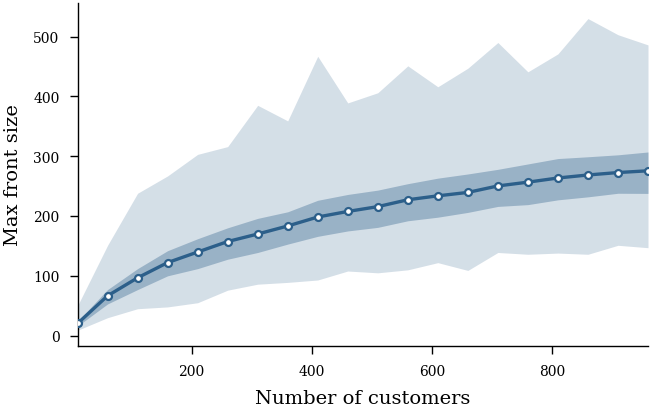

In [7]:
plot_experiment('customer_cnt', customer_values, res_customers,
               xlabel='Number of customers')
plt.tight_layout()
plt.savefig("../.output/customer_cnt_sweep.png")
plt.show()

## Experiment 2 — Number of charging stations

In [28]:
cs_values = list(range(2, 20))
res_cs = collect_front_sizes('charging_station_cnt', cs_values)

with open("../.output/charging_station_cnt_sweep.json", "w") as f:
    json.dump(res_cs, f)

charging_station_cnt: 100%|██████████| 18/18 [13:56<00:00, 46.46s/it]


In [103]:
cs_values = list(range(2, 20))
with open("../.output/charging_station_cnt_sweep.json", "r") as f:
    res_cs = json.load(f)

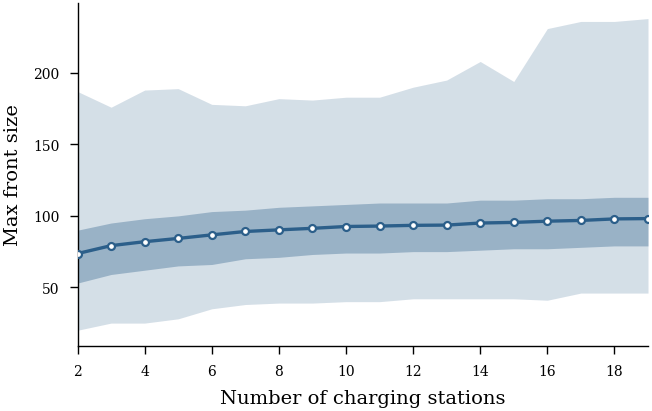

In [114]:
plot_experiment('charging_station_cnt', cs_values, res_cs,
               xlabel='Number of charging stations')
plt.tight_layout()
plt.savefig("../.output/charging_station_cnt_sweep.png")
plt.show()

## Experiment 3 — Battery capacity

In [17]:
battery_values = list(np.arange(1.4, 3, 0.1))
res_battery = collect_front_sizes('battery_capacity', battery_values)

with open("../.output/battery_capacity_sweep.json", "w") as f:
    json.dump(res_battery, f)

battery_capacity: 100%|██████████| 16/16 [08:37<00:00, 32.33s/it]


In [105]:
battery_values = list(np.arange(1.4, 3, 0.1))
with open("../.output/battery_capacity_sweep.json", "r") as f:
    res_battery = json.load(f)

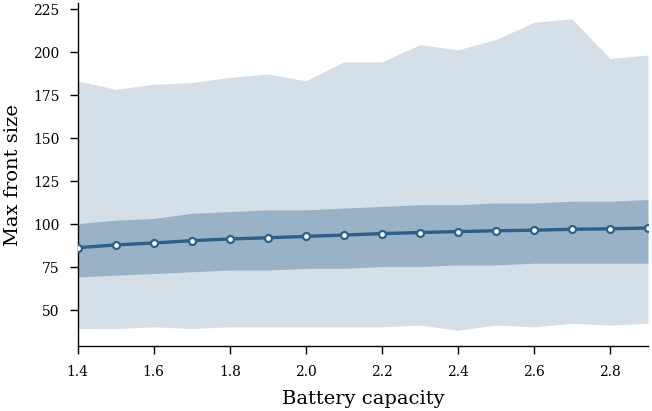

In [115]:
plot_experiment('battery_capacity', battery_values, res_battery,
               xlabel='Battery capacity')
plt.tight_layout()
plt.savefig("../.output/battery_capacity_sweep.png")
plt.show()

## Experiment 4 — Cargo capacity (affects demand range)

In [25]:
cargo_values = list(range(50, 300, 15))
res_cargo = collect_front_sizes('cargo_capacity', cargo_values)

with open("../.output/cargo_capacity_sweep.json", "w") as f:
    json.dump(res_cargo, f)

cargo_capacity: 100%|██████████| 17/17 [08:19<00:00, 29.38s/it]


In [107]:
cargo_values = list(range(50, 300, 15))
with open("../.output/cargo_capacity_sweep.json", "r") as f:
    res_cargo = json.load(f)

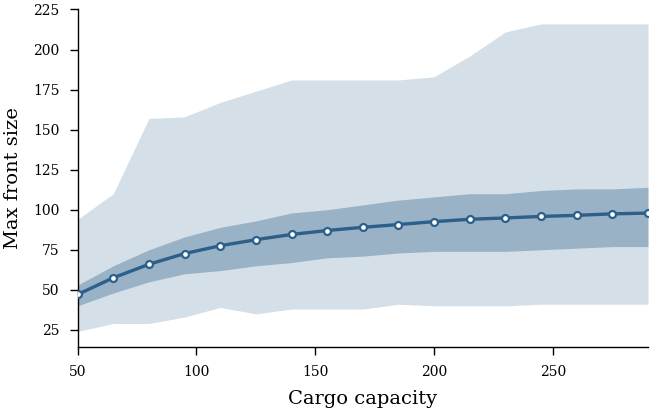

In [116]:
plot_experiment('cargo_capacity', cargo_values, res_cargo,
               xlabel='Cargo capacity')
plt.tight_layout()
plt.savefig("../.output/cargo_capacity_sweep.png")
plt.show()